#Prédiction de l'évolution du diabète



#Introduction

Dans ce projet, nous avons travaillé sur le dataset Diabetes de scikit-learn. Ce jeu de données regroupe 442 patients diabétiques, décrits par 10 variables médicales : l'âge, le sexe, l'IMC, la pression artérielle, et six mesures sanguines comme le cholestérol, le LDL ou encore la glycémie. La variable cible est quantitative : elle mesure la progression de la maladie un an après le début de l'étude. L'objectif du projet est de comparer plusieurs méthodes d'apprentissage supervisé pour prédire cette progression.

In [ ]:
# ======== Import des outils/données généraux ========
from sklearn.datasets import load_diabetes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ======== Import des outils de Machine Learning ========

# Régression Linéaire
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.model_selection import TimeSeriesSplit

# Méthode des K-plus proches voisins
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold, cross_validate,cross_val_score
from sklearn.neighbors import KNeighborsRegressor

Le dataset Diabetes de scikit-learn contient 442 patients diabétiques avec 10 variables explicatives et une cible quantitative.

Colonnes X (10 features) :
- age : âge en années
- sex : sexe (codé)
- bmi : indice de masse corporelle
- bp : pression artérielle
- s1 à s6 : 6 mesures sanguines

Target y : progression de la maladie (1 an après le début de l'étude)

Tableau descpritif précis de X :

     0     age                        Âge
     1     sex                       Sexe     
     2     bmi Indice de masse corporelle
     3      bp        Pression artérielle
     4      s1          Cholestérol total
     5      s2                        LDL
     6      s3                        HDL
     7      s4          Ratio cholestérol
     8      s5        Triglycérides (log)
     9      s6                   Glycémie

In [ ]:
# ======== Import et Préparation des données ========

#Variable globale

data = load_diabetes(as_frame=True)
df = data.frame
Features = data.feature_names



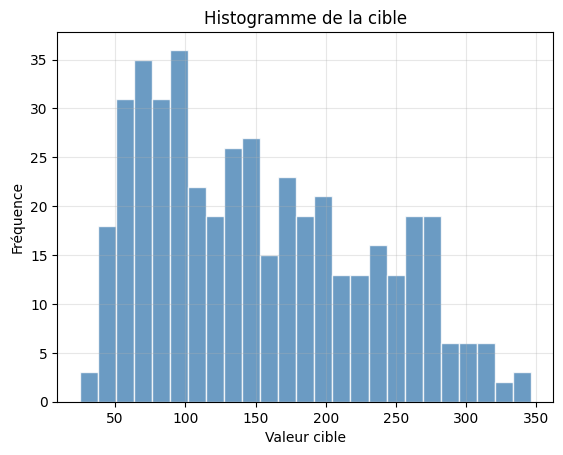

In [ ]:
# ======== Affichage des données ========

# Histogramme de la cible

plt.hist(df["target"], bins=25, color="steelblue", edgecolor="white", alpha=0.8)
plt.xlabel("Valeur cible")
plt.ylabel("Fréquence")
plt.title("Histogramme de la cible")
plt.grid(True, alpha=0.3)
plt.show()



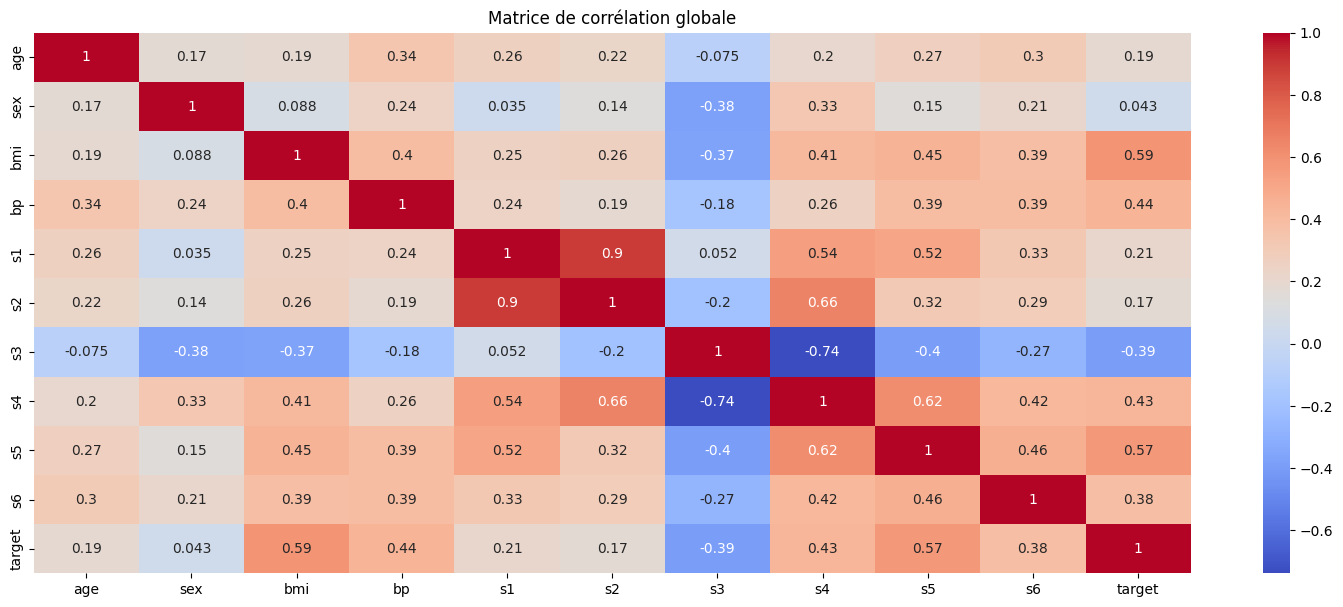

In [ ]:
# Corrélation features / cible

corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(15,6))
sns.heatmap(corr_matrix,annot=True, cmap="coolwarm")
plt.tight_layout()
plt.title("Matrice de corrélation globale")
plt.show()

# Régréssion Classique, Ridge, Lasso

                     Ridge        Lasso
Alpha Optimal     0.151135     0.101090
R² score          0.461455     0.471861
MSE            2853.291192  2798.158667


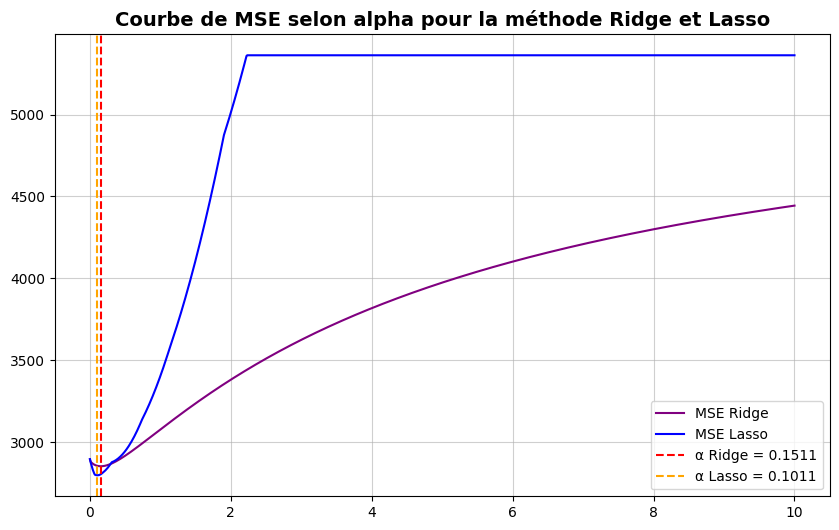

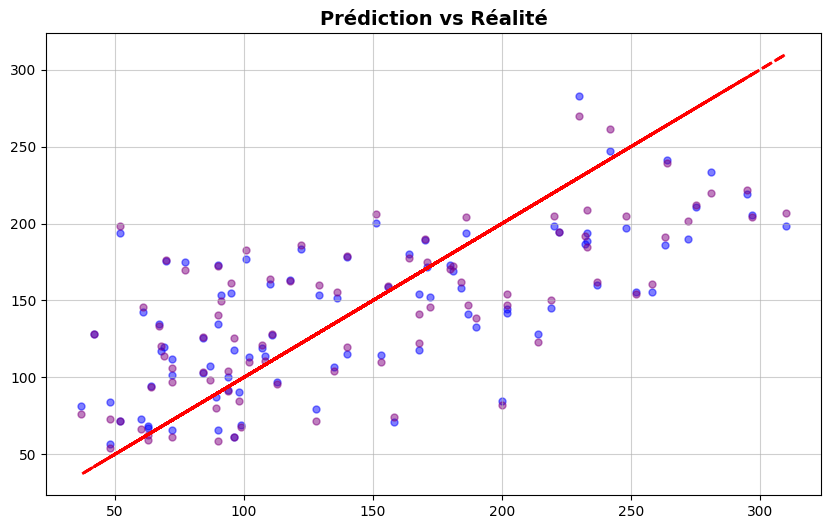

In [ ]:
# ======== Partie A : Régression Linéaire (Ridge et Lasso) ========

# Création des variables X et Y

X = df[Features].values
Y = df["target"].values

X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2, random_state=42)

# === Régression Ridge et Lasso avec meilleur alpha ===

alphas = np.linspace(0.001,10,1000)

# Détermination du meilleur alpha pour la méthode Ridge et Lasso

ridge_tab = []
lasso_tab = []

for alpha in alphas:

    ridge = Ridge(alpha)
    ridge.fit(X_train,Y_train)
    Y_ridge = ridge.predict(X_test)

    lasso = Lasso(alpha)
    lasso.fit(X_train,Y_train)
    Y_lasso = lasso.predict(X_test)

    ridge_tab.append(mean_squared_error(Y_test,Y_ridge))
    lasso_tab.append(mean_squared_error(Y_test,Y_lasso))

best_ridge_alpha = alphas[np.argmin(ridge_tab)]
best_lasso_alpha = alphas[np.argmin(lasso_tab)]

# Computation de la méthode de Régression Ridge

ridge = Ridge(best_ridge_alpha)
ridge.fit(X_train,Y_train)
Y_ridge = ridge.predict(X_test)

# Computation de la méthode de Régression Lasso

lasso = Lasso(best_lasso_alpha, max_iter=5000)
lasso.fit(X_train,Y_train)
Y_lasso = lasso.predict(X_test)

# === Présentation des mesures ===

alpha1,alpha2 = best_ridge_alpha, best_lasso_alpha
R2_1,R2_2 = r2_score(Y_test, Y_ridge),r2_score(Y_test, Y_lasso)
MSE1,MSE2 = mean_squared_error(Y_test, Y_ridge), mean_squared_error(Y_test, Y_lasso)

results = pd.DataFrame(
    [[alpha1, alpha2],
     [R2_1,R2_2],
     [MSE1, MSE2]],
    columns=['Ridge', 'Lasso'],
    index=['Alpha Optimal', 'R² score', 'MSE']
)
print(results)

# === Affichage ===

# MSE Ridge/Lasso

mse_values_ridge = mean_squared_error(Y_test,Y_ridge) # Tableau qui contient chaque MSE pour chaque alpha
mse_values_lasso = mean_squared_error(Y_test,Y_lasso) # Pareil pour Régression Lasso

plt.figure(figsize=(10,6))
plt.plot(alphas,ridge_tab,color='purple',label='MSE Ridge') # Ridge
plt.plot(alphas,lasso_tab,color='blue',label='MSE Lasso') # Lasso
plt.axvline(best_ridge_alpha, color='red',    linestyle='--', label=f'α Ridge = {best_ridge_alpha:.4f}')  # Best alpha Ridge
plt.axvline(best_lasso_alpha, color='orange', linestyle='--', label=f'α Lasso = {best_lasso_alpha:.4f}') # Best alpha Lasso
plt.title("Courbe de MSE selon alpha pour la méthode Ridge et Lasso",fontsize='14',fontweight='bold')
plt.legend()
plt.grid(alpha=0.6)
plt.show()

# Nuage de point et droite de régression selon les deux méthodes

plt.figure(figsize=(10,6))
plt.scatter(Y_test,Y_ridge,s=25,label='Modèle Ridge',alpha=0.5, color='blue')
plt.scatter(Y_test,Y_lasso,s=25,label='Modèle Lasso',alpha=0.5, color='purple')
plt.plot(Y_test,Y_test, color='red',linestyle='--',linewidth=2,label='Régression parfaite')
plt.title("Prédiction vs Réalité",fontsize=14,fontweight='bold')
plt.grid(alpha=0.6)
plt.show()


# Analyse des résultats de régression

## 1. Interprétation des mesures

- **MSE élevé** :  
  - Ridge : 2853.3  
  - Lasso : 2798.2  

  Le MSE (Mean Squared Error) des deux modèles sont relativements très élevés. On en déduit que notre modèle n'est pas assez performant, ce qui est clairement visible sur le second graphique.

- **Alphas optimaux très proches de 0** :  
  - Ridge : 0.151  
  - Lasso : 0.101  

   Les alphas optimaux pour la méthode de régression Ridge et Lasso son très proches de 0. Ce qui permet de voir que ces deux méthodes ne sont pas pertinentes pour ce modèle et que la régression linéaire classique est plus intéressante.

&nbsp;

## 2. Formules des méthodes de régression

- **Ridge :**  
$$
\widehat{\beta}^{\mathrm{ridge}}(\alpha)
= \arg\min_{\beta \in \mathbb{R}^p}
\Big\{ \|y - X\beta\|_2^2 + \alpha \|\beta\|_2^2 \Big\}
$$

- **Lasso :**  
$$
\widehat{\beta}^{\mathrm{lasso}}(\alpha)
= \arg\min_{\beta \in \mathbb{R}^p}
\Big\{ \|y - X\beta\|_2^2 + \alpha \|\beta\|_1 \Big\}
$$

- **OLS :**  
$$
\widehat{\beta}^{\mathrm{OLS}}
= \arg\min_{\beta \in \mathbb{R}^p} \|y - X\beta\|_2^2
$$

Donc pour un alpha proche de 0, on a :  
$$
\widehat{\beta}^{\mathrm{OLS}} \approx \widehat{\beta}^{\mathrm{ridge}} \approx \widehat{\beta}^{\mathrm{lasso}}
$$

&nbsp;

## 3. Explications et pistes d’amélioration


- **Pourquoi le MSE est élevé ?**  
   Ceci peut s'expliquer par beaucoup d'argument, mais un argument simple est que nos features ne sont pas assez explicatives sur la variable cible ou qu'il n'y a pas assez de données représentative pour notre modèle

- **Pourquoi les régressions Ridge et Lasso sont non pertinentes ?**  
  Cela est du au fait que même si les features sont multicorrélées (ce qui pourrait rendre Ridge et Lasso pertinent), il n'y a pas assez de features pour que ces différences soient prises en compte dans les deux autres méthodes.



- **Comment les rendre pertinentes ?**  
  On peut alors ajouter des features pertinentes, corrélées ou transformées ou augmenter le nombre de données  



- **Comment améliorer OLS ?**  
  En ajoutant ou transformer des variables explicatives  
  

                     Ridge        Lasso
Alpha Optimal     0.331297     0.411369
R² score          0.431366     0.444713
MSE            3012.707879  2941.996962

Lasso a annulé 9/31 coefficients (features ignorées)


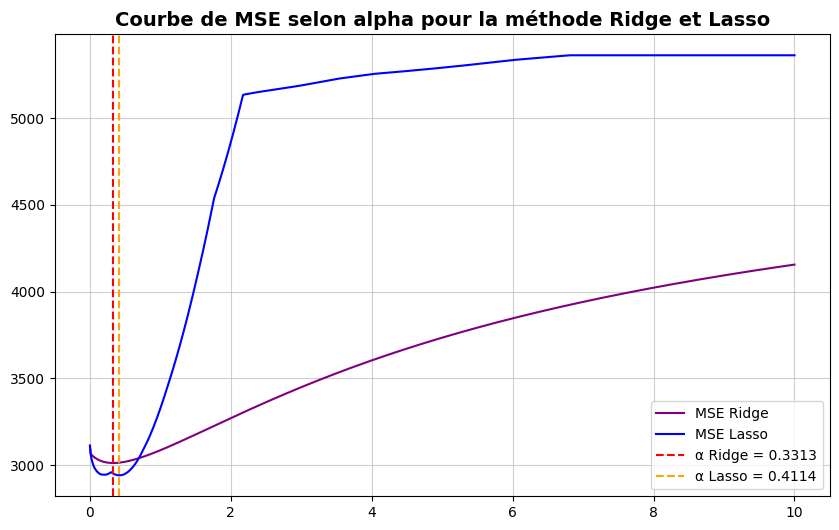

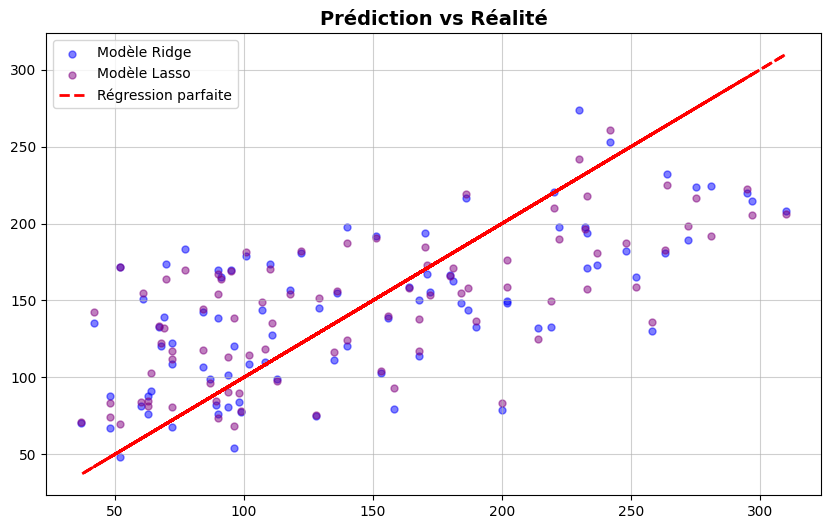

In [ ]:
# ======== Partie D : Régression Linéaire (Ridge et Lasso) avec nouvelles features corréléees ========

# Création des variables X et Y

X_base, Y = load_diabetes(return_X_y=True)

noise = np.random.randn(X_base.shape[0], 20) # On crée du bruit
X_noisy = np.hstack([X_base, noise]) # Concaténation avec X
X_noisy = np.hstack([X_noisy, X_base[:, [2]] + 0.01 * np.random.randn(X_base.shape[0], 1)]) # On crée une feature très semblable a celle déja existante

X = X_noisy

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)


# === Régression Ridge et Lasso avec meilleur alpha ===

alphas = np.linspace(0.001,10,1000)

# Détermination du meilleur alpha pour la méthode Ridge et Lasso

ridge_tab = []
lasso_tab = []

for alpha in alphas:

    ridge = Ridge(alpha)
    ridge.fit(X_train,Y_train)
    Y_ridge = ridge.predict(X_test)

    lasso = Lasso(alpha, max_iter=5000)
    lasso.fit(X_train,Y_train)
    Y_lasso = lasso.predict(X_test)

    ridge_tab.append(mean_squared_error(Y_test,Y_ridge))
    lasso_tab.append(mean_squared_error(Y_test,Y_lasso))

best_ridge_alpha = alphas[np.argmin(ridge_tab)]
best_lasso_alpha = alphas[np.argmin(lasso_tab)]

# Computation de la méthode de Régression Ridge

ridge = Ridge(best_ridge_alpha)
ridge.fit(X_train,Y_train)
Y_ridge = ridge.predict(X_test)

# Computation de la méthode de Régression Lasso

lasso = Lasso(best_lasso_alpha, max_iter=5000)
lasso.fit(X_train,Y_train)
Y_lasso = lasso.predict(X_test)

# === Présentation des mesures ===

alpha1,alpha2 = best_ridge_alpha, best_lasso_alpha
R2_1,R2_2 = r2_score(Y_test, Y_ridge),r2_score(Y_test, Y_lasso)
MSE1,MSE2 = mean_squared_error(Y_test, Y_ridge), mean_squared_error(Y_test, Y_lasso)

results = pd.DataFrame(
    [[alpha1, alpha2],
     [R2_1,R2_2],
     [MSE1, MSE2]],
    columns=['Ridge', 'Lasso'],
    index=['Alpha Optimal', 'R² score', 'MSE']
)
print(results)

# Calcul du nombres de features supprimées par la régression Lasso

n_zero = np.sum(lasso.coef_ == 0)
n_total = len(lasso.coef_)
print(f"\nLasso a annulé {n_zero}/{n_total} coefficients (features ignorées)")

# === Affichage ===

# MSE en fonction de alpha

plt.figure(figsize=(10, 6))
plt.plot(alphas, ridge_tab, color='purple', label='MSE Ridge')
plt.plot(alphas, lasso_tab, color='blue',   label='MSE Lasso')
plt.axvline(best_ridge_alpha, color='red',    linestyle='--', label=f'α Ridge = {best_ridge_alpha:.4f}')
plt.axvline(best_lasso_alpha, color='orange', linestyle='--', label=f'α Lasso = {best_lasso_alpha:.4f}')
plt.title("Courbe de MSE selon alpha pour la méthode Ridge et Lasso", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.6)
plt.show()

# Nuage de point et droite de régression selon les deux méthodes

plt.figure(figsize=(10, 6))
plt.scatter(Y_test, Y_ridge, s=25, label='Modèle Ridge', alpha=0.5, color='blue')
plt.scatter(Y_test, Y_lasso, s=25, label='Modèle Lasso', alpha=0.5, color='purple')
plt.plot(Y_test, Y_test, color='red', linestyle='--', linewidth=2, label='Régression parfaite')
plt.title("Prédiction vs Réalité", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.6)
plt.show()



## Résultat de la partie D

### 1. Avantage de la modification artificielle des données

On voit qu'en rajoutant du bruit sur les features, les alphas optimaux diffèrent totalement de ce qui a résulté d'avant. Ce qui montre bien qu'ajouter des nouvelles features corrélées permet de mettre en avant les deux méthodes.

&nbsp;

### 2. Limites claires de cette modification

 On remarque une limite claire : le MSE trouvé dans la partie précédente reste meilleure que celui d'avant, ce qui justifie bien le fait que la régréssion classique appliquée à ce modèle reste la plus pertinente.

          Modèle de base  Nouveaux modèle
R² score        0.452603         0.486306
MSE          2900.193628      2721.630765


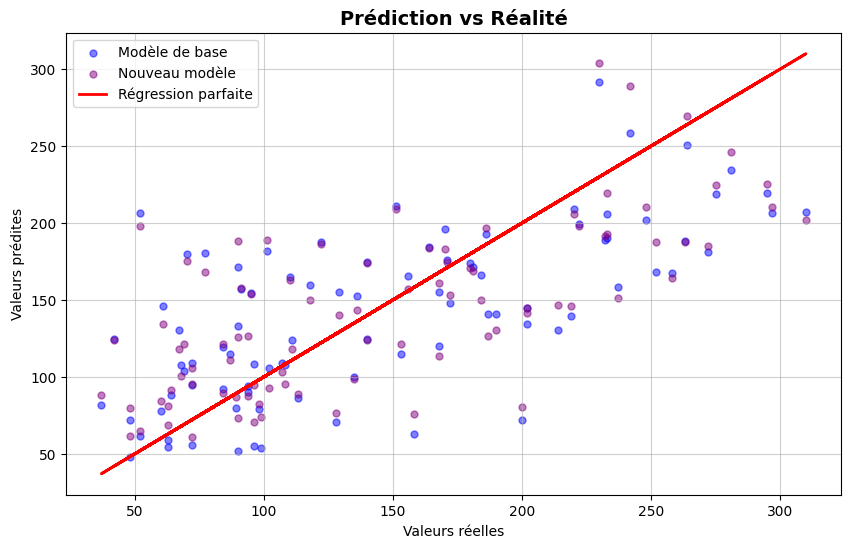

In [ ]:
# ======== Partie E : Régression inéaire classique avec nouvelles features  ========

# === Création de nouvelle features et variables ===

bmi_x_bp  = X_base[:, 2] * X_base[:, 3] # BMI × pression artérielle
bmi_x_s5  = X_base[:, 2] * X_base[:, 8] # BMI × triglycérides
age_x_bmi = X_base[:, 0] * X_base[:, 2] # BMI x âge

bmi_squared = X_base[:, 2] ** 2
s5_squared  = X_base[:, 8] ** 2

new_features = np.column_stack([bmi_x_bp, bmi_x_s5, age_x_bmi, bmi_squared, s5_squared]) # On met en une matrice les nouvelles features
X_new = np.hstack([X_base, new_features]) # On concaténe la matrice aux données précédentes

X_train_base, X_test_base, Y_train, Y_test = train_test_split(X_base,     Y, test_size=0.2, random_state=42)
X_train_new,  X_test_new,  _,      _       = train_test_split(X_new, Y, test_size=0.2, random_state=42)

scaler_base = StandardScaler()
X_train_base = scaler_base.fit_transform(X_train_base)
X_test_base  = scaler_base.transform(X_test_base)

scaler_new = StandardScaler()
X_train_new = scaler_new.fit_transform(X_train_new)
X_test_new  = scaler_new.transform(X_test_new)

# Computation de la méthode de régression linéaire classique et améliorée

model_base = LinearRegression()
model_base.fit(X_train_base, Y_train)
Y_pred_base = model_base.predict(X_test_base)

model_new = LinearRegression()
model_new.fit(X_train_new, Y_train)
Y_pred_new = model_new.predict(X_test_new)

# ==== Présentation des mesures ====

results = pd.DataFrame(
    [[r2_score(Y_test, Y_pred_base),r2_score(Y_test, Y_pred_new)],
     [mean_squared_error(Y_test, Y_pred_base), mean_squared_error(Y_test, Y_pred_new)]],
    columns=['Modèle de base', 'Nouveaux modèle'],
    index=['R² score', 'MSE']
)
print(results)

# ==== Affichage ====

plt.figure(figsize=(10, 6))
plt.scatter(Y_test, Y_pred_base, s=25, alpha=0.5, color='blue',   label='Modèle de base')
plt.scatter(Y_test, Y_pred_new,  s=25, alpha=0.5, color='purple', label='Nouveau modèle')
plt.plot(Y_test, Y_test, color='red', linewidth=2, label='Régression parfaite')
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Prédiction vs Réalité", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.6)
plt.show()


### Résultat de la Partie E

On voit que même en essayant de rajouter des nouvelles features, notre modèle OLS ne s'améliore pas drastiquement. Cela s'explique par le fait que les 10 features de base contiennent l'essentiel de l'information disponible. Les nouvelles features ajoutées restent toujours des combinaisons des mêmes features.

**D'où vient donc la limite ?**

Ici on comprend que notre modèle n'est pas bon non pas parce que l'on a pris le mauvais modèle de régression linéaire (Ridge et Lasso donnent des résultats encores plus pire), mais aussi parce que le dataset possède ses propres limites : pas assez de features, pas assez de données.


# **Conclusion de la partie Régression Linéaire**

Cette première partie d'étude nous a permis de comparer trois méthodes de régression sur le dataset **diabetes** de scikit-learn : la régression linéaire classique, la régression Ridgeet la régression Lasso.

- Régression classique  :  R² ≈ 0.45,  MSE ≈ 2900
- Régression Ridge      :  R² ≈ 0.47,  MSE ≈ 2853.3
- Régression Lasso      : R² ≈ 0.46,  MSE ≈ 2798.1

  Contre-intuitivement, la régression classique obtient ici les meilleures
  performances, devant Ridge et Lasso.

Il n'existe pas de méthode **universellement** supérieure. Le choix du modèle
dépend avant tout des caractéristiques du dataset

Cette étude illustre qu'augmenter la complexité du modèle n'améliore pas
nécessairement les performances. La simplicité, la lisibilité et
l'adéquation au problème restent les critères premiers du choix d'un modèle.


#   MÉTHODE DES K-PLUS PROCHES VOISINS (KNN) — RÉGRESSION

In [ ]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)



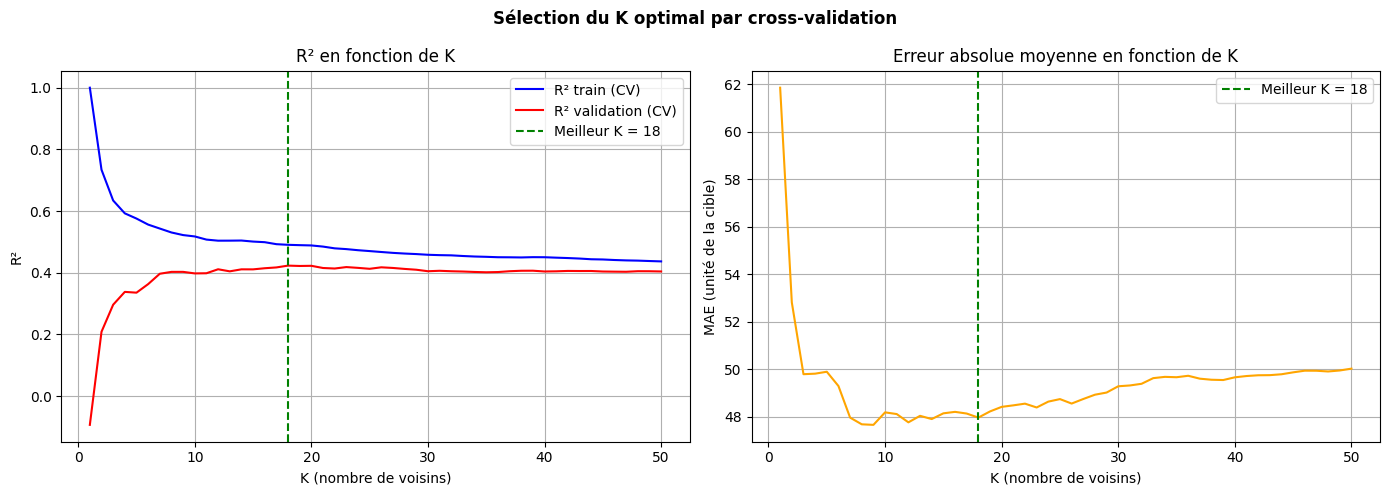


Meilleur K (sélectionné par CV sur le train) : K = 18
R² de validation croisée associé : 0.4229
MAE de validation croisée associée : 47.97


In [ ]:
# ======== SÉLECTION DU MEILLEUR K PAR CROSS-VALIDATION ===================

kf = KFold(n_splits=5, shuffle=True, random_state=42)

K_range         = range(1, 51)
cv_r2_train     = []
cv_r2_val       = []
cv_mae_val      = []

for k in K_range:
    knn_reg = KNeighborsRegressor(n_neighbors=k)

    results = cross_validate(
        knn_reg,
        X_train, y_train,
        cv                = kf,
        scoring           = ["r2", "neg_mean_absolute_error"],
        return_train_score= True
    )
    cv_r2_train.append(results["train_r2"].mean())
    cv_r2_val.append(results["test_r2"].mean())
    cv_mae_val.append(-results["test_neg_mean_absolute_error"].mean())


best_k        = list(K_range)[np.argmax(cv_r2_val)]
best_r2_cv    = max(cv_r2_val)
best_mae_cv   = cv_mae_val[np.argmax(cv_r2_val)]


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Sélection du K optimal par cross-validation", fontweight="bold")

axes[0].plot(K_range, cv_r2_train, label="R² train (CV)", color="blue")
axes[0].plot(K_range, cv_r2_val,   label="R² validation (CV)", color="red")
axes[0].axvline(best_k, color="green", linestyle="--", label=f"Meilleur K = {best_k}")
axes[0].set_xlabel("K (nombre de voisins)")
axes[0].set_ylabel("R²")
axes[0].set_title("R² en fonction de K")
axes[0].legend()
axes[0].grid(True)


axes[1].plot(K_range, cv_mae_val, color="orange")
axes[1].axvline(best_k, color="green", linestyle="--", label=f"Meilleur K = {best_k}")
axes[1].set_xlabel("K (nombre de voisins)")
axes[1].set_ylabel("MAE (unité de la cible)")
axes[1].set_title("Erreur absolue moyenne en fonction de K")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


print(f"\nMeilleur K (sélectionné par CV sur le train) : K = {best_k}")
print(f"R² de validation croisée associé : {best_r2_cv:.4f}")
print(f"MAE de validation croisée associée : {best_mae_cv:.2f}")


#Choix du nombre de voisins

La cross-validation à 5 plis identifie K = 18 comme valeur optimale. Sur les graphiques, on observe que le R² d'entraînement est élevé pour les petits K (surapprentissage fort à K=1) et diminue progressivement, tandis que le R² de validation forme un plateau entre K ≈ 15 et K ≈ 25. Ce plateau indique que la performance est relativement stable dans cette plage, et que le modèle n'est pas très sensible au choix précis de K autour de cette valeur.
La MAE de validation croisée de 47.97 signifie qu'en moyenne, les prédictions se trompent de 48 points sur l'échelle de la cible (qui s'étend de ~25 à ~346). C'est une erreur non négligeable, cohérente avec les limites du dataset.

  R² train     : 0.5015  
  R² test      : 0.4179  
  MAE test     : 45.54  
  MSE test     : 3083.90  


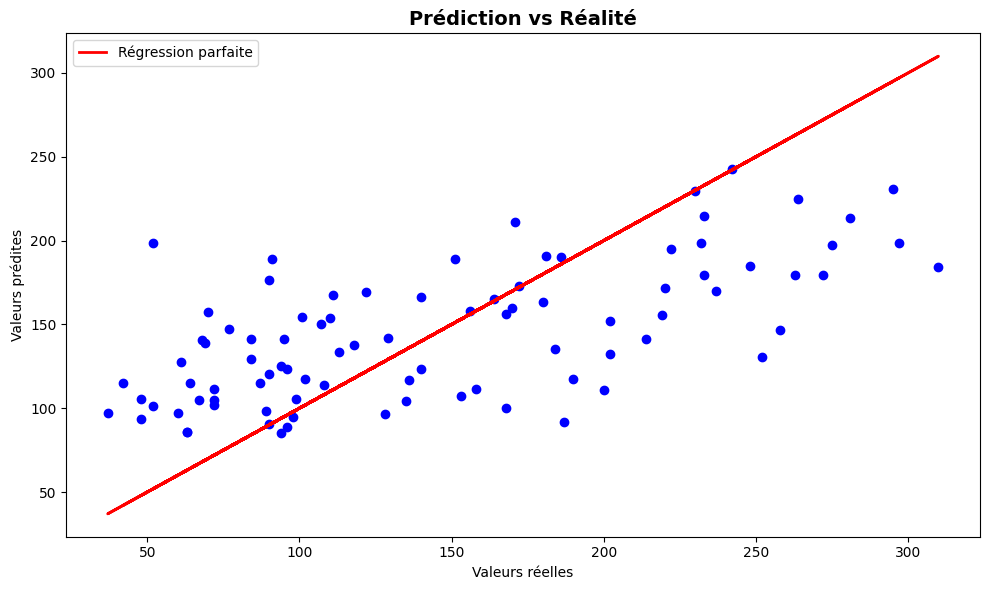

In [ ]:
knn_final = KNeighborsRegressor(n_neighbors=best_k)
knn_final.fit(X_train, y_train)


# ======== 9. ÉVALUATION FINALE SUR LE JEU DE TEST ===========================


y_pred_test  = knn_final.predict(X_test)
y_pred_train = knn_final.predict(X_train)

# Métriques sur le test

mse_test  = mean_squared_error(y_test, y_pred_test)
mae_test  = mean_absolute_error(y_test, y_pred_test)
r2_test   = r2_score(y_test, y_pred_test)

# Métriques sur le train


r2_train   = r2_score(y_train, y_pred_train)


print(f"  R² train     : {r2_train:.4f}  ")
print(f"  R² test      : {r2_test:.4f}  ")
print(f"  MAE test     : {mae_test:.2f}  ")
print(f"  MSE test     : {mse_test:.2f}  ")


# ======== VISUALISATIONS FINALES =========================================

plt.figure(figsize=(10,6))
plt.scatter(y_test,y_pred_test, color='blue')
plt.plot(y_test,y_test, color='red',linewidth=2,label='Régression parfaite')
plt.title("Prédiction vs Réalité",fontsize=14,fontweight='bold')
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.legend()
plt.tight_layout()
plt.show()





# Analyse des résultats de régression (k-NN)

## 1. Interprétation des mesures

- R² train : 0.5015

- R² test  : 0.4179

- MAE test : 45.54

- MSE test : 3083.90

L'écart entre le R² train (0.50) et le R² test (0.42) révèle un léger surapprentissage : le modèle mémorise mieux les exemples d'entraînement qu'il ne généralise sur les données inédites. Ce phénomène est typique du KNN avec un K modéré.
Avec un MSE de 3083 et une MAE de 45.5, les performances sont comparables à celles de la régression linéaire (MSE ≈ 2800–2900), sans la dépasser. Le KNN n'apporte donc pas de gain notable sur ce dataset dans cette configuration. Le graphique Prédiction vs Réalité confirme cette tendance : les prédictions convergent trop vers la moyenne pour les valeurs extrêmes, phénomène dit de régression vers la moyenne, inhérent à l'algorithme KNN.

&nbsp;

## 2. Formule de la méthode

- **K-Nearest Neighbors (Regression) :** La prédiction $\widehat{y}$ pour une nouvelle observation $x$ est la moyenne des valeurs cibles $y_i$ de ses $K$ plus proches voisins (notés $\mathcal{N}_K(x)$) :

$$
\widehat{f}(x) = \frac{1}{K} \sum_{x_i \in \mathcal{N}_K(x)} y_i
$$



&nbsp;



In [ ]:
# ======== ANALYSE EN COMPOSANTES PRINCIPALES (ACP) ========================


matrice_corr = X_train.corr().to_numpy()

valeurs_propres, vecteurs_propres = np.linalg.eigh(matrice_corr)
idx              = np.argsort(valeurs_propres)[::-1]
valeurs_propres  = valeurs_propres[idx]
vecteurs_propres = vecteurs_propres[:, idx]

variance_expliquee = valeurs_propres / np.sum(valeurs_propres)
variance_cumulee   = np.cumsum(variance_expliquee)

proj_train = X_train.to_numpy() @ vecteurs_propres
proj_test  = X_test.to_numpy()  @ vecteurs_propres

correlation_variables = vecteurs_propres * np.sqrt(valeurs_propres)
correlation_df = pd.DataFrame( correlation_variables, index  = X_train.columns, columns= [f"CP{i+1}" for i in range(len(valeurs_propres))])

print("Variance cumulée : ",variance_cumulee)

Variance cumulée :  [0.39688108 0.54467848 0.6698445  0.77093158 0.83676055 0.89611157
 0.94814822 0.99151325 0.99907676 1.        ]


In [ ]:
# ======== KNN SUR LES COMPOSANTES PRINCIPALES ===================

for n_comp in range(2,10):
    X_train_acp = proj_train[:, :n_comp]
    X_test_acp  = proj_test[:, :n_comp]

    cv_r2_acp = []
    for k in K_range:
        res = cross_validate(
            KNeighborsRegressor(n_neighbors=k),
            X_train_acp, y_train,
            cv=KFold(5, shuffle=True, random_state=42),
            scoring="r2"
        )
        cv_r2_acp.append(res["test_score"].mean())

    best_k_acp = list(K_range)[np.argmax(cv_r2_acp)]
    knn_acp    = KNeighborsRegressor(n_neighbors=best_k_acp)
    knn_acp.fit(X_train_acp, y_train)
    r2_acp     = r2_score(y_test, knn_acp.predict(X_test_acp))
    print(f"  {n_comp} composantes :best K={best_k_acp:2d},  R² test = {r2_acp:.4f}")

print(f"\n  Référence (10 features) :  best K={best_k:2d},  R² test = {r2_test:.4f}")


  2 composantes :best K=35,  R² test = 0.3309
  3 composantes :best K=13,  R² test = 0.3069
  4 composantes :best K=22,  R² test = 0.4613
  5 composantes :best K=29,  R² test = 0.4216
  6 composantes :best K=35,  R² test = 0.4389
  7 composantes :best K=21,  R² test = 0.4319
  8 composantes :best K=19,  R² test = 0.4276
  9 composantes :best K=18,  R² test = 0.4203

  Référence (10 features) : best K=18,  R² test = 0.4179


# Analyse de la réduction de dimension (PCA + k-NN)

- Meilleur : 4 composantes : K=22,  R² test = 0.4613


Le meilleur R² est obtenu avec 4 composantes principales (R² = 0.461), surpassant le modèle avec les 10 features originales (R² = 0.418). Ce résultat contre-intuitif s'explique par la malédiction de la dimensionnalité : en haute dimension, les distances euclidiennes utilisées par le KNN deviennent moins discriminantes, et certaines dimensions introduisent du bruit.

La variance cumulée montre que 4 composantes capturent 77% de l'information. Les 6 composantes restantes n'ajoutent que de la redondance ou du bruit pour le KNN, d'où la dégradation progressive des performances au-delà de 4 dimensions.
On remarque aussi une forte instabilité du K optimal (entre 13 et 35 selon le nombre de composantes), ce qui traduit que la géométrie de voisinage change profondément d'un espace à l'autre.


          Modèle de base  Modèle enrichi
R² score        0.417929        0.411816
MSE          3083.900333     3116.287843


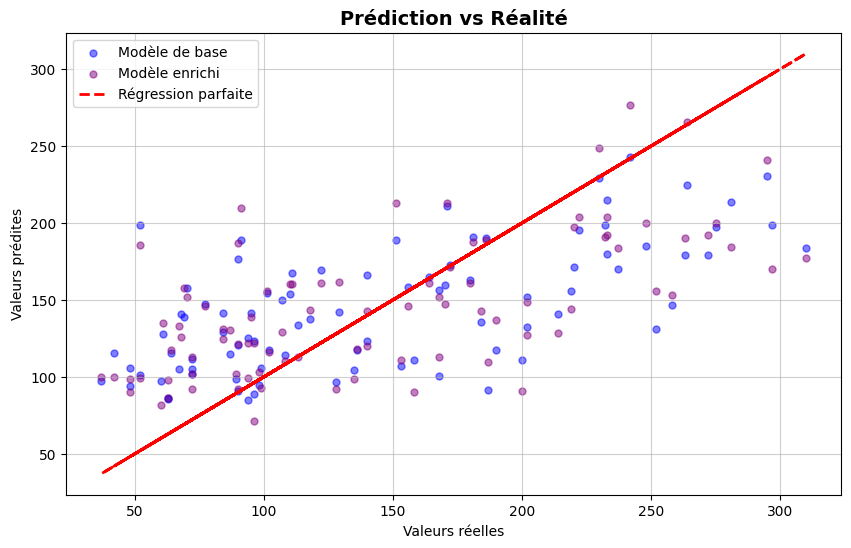

In [ ]:
# ======== KNN SUR LA BASE DE DONNEE ENRICHIE ===================

K_range         = range(1, 51)
cv_r2_train_enr     = []
cv_r2_val_enr       = []
cv_mae_val_enr      = []


for k in K_range:
    knn_reg = KNeighborsRegressor(n_neighbors=k)

    results_enr = cross_validate(
        knn_reg,
        X_train_new, y_train,
        cv                = kf,
        scoring           = ["r2", "neg_mean_absolute_error"],
        return_train_score= True
    )
    cv_r2_train_enr.append(results_enr["train_r2"].mean())
    cv_r2_val_enr.append(results_enr["test_r2"].mean())
    cv_mae_val_enr.append(-results_enr["test_neg_mean_absolute_error"].mean())


best_k_enr        = list(K_range)[np.argmax(cv_r2_val_enr)]
best_r2_cv_enr    = max(cv_r2_val_enr)
best_mae_cv_enr   = cv_mae_val_enr[np.argmax(cv_r2_val_enr)]

knr_enr = KNeighborsRegressor(n_neighbors=best_k_enr)
knr_enr.fit(X_train_new, y_train)
Y_pred_enr = knr_enr.predict(X_test_new)

# ==== Présentation des mesures ====
results = pd.DataFrame(
    [[r2_score(y_test, y_pred_test),           r2_score(y_test, Y_pred_enr)],
     [mean_squared_error(Y_test, y_pred_test), mean_squared_error(y_test, Y_pred_enr)]],
    columns=['Modèle de base', 'Modèle enrichi'],
    index=['R² score', 'MSE']
)
print(results)

# ==== Affichage ====

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_test, s=25, alpha=0.5, color='blue',   label='Modèle de base')
plt.scatter(y_test, Y_pred_enr,  s=25, alpha=0.5, color='purple', label='Modèle enrichi')
plt.plot(y_test, y_test, color='red', linestyle='--', linewidth=2, label='Régression parfaite')
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Prédiction vs Réalité", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.6)
plt.show()

# Analyse de l'enrichissement des données (Feature Engineering)

Modèle de base    

- R² score :      0.4179       

- MSE   :       3083.90              

Modèle enrichi

- R² score :    0.4118
- MSE :                       3116.29

Contrairement à ce qui était observé pour la régression linéaire OLS, l'ajout de features polynomiales et d'interactions dégrade légèrement les performances du KNN : le R² baisse de 0.418 à 0.412 et le MSE augmente de 3084 à 3116.
Ce résultat s'explique par le fait que le KNN est particulièrement sensible à la dimensionnalité : passer de 10 à 15 features augmente l'espace de recherche de voisins, ce qui dilue les distances et nuit à la qualité du voisinage. Les nouvelles features, bien qu'informatives pour un modèle linéaire, introduisent ici de la confusion géométrique.
On conclut que pour le KNN, la réduction de dimension (ACP à 4 composantes) est une stratégie bien plus efficace que l'enrichissement des features. Moins de dimensions mais mieux choisies, voilà la clé pour cet algorithme.


#Conclusion

Ce projet nous a permis de comparer deux grandes familles de méthodes supervisées. Sur le dataset Diabetes, aucun modèle n'atteint des performances très élevées — le R² plafonne autour de 0,47 — ce qui reflète les limites intrinsèques du jeu de données. Néanmoins, nous retenons que la complexité n'est pas toujours synonyme de performance, que la régularisation n'est utile qu'en présence de multicolinéarité, et que la réduction de dimension peut améliorer un algorithme sensible à la malédiction de la dimensionnalité comme le KNN.